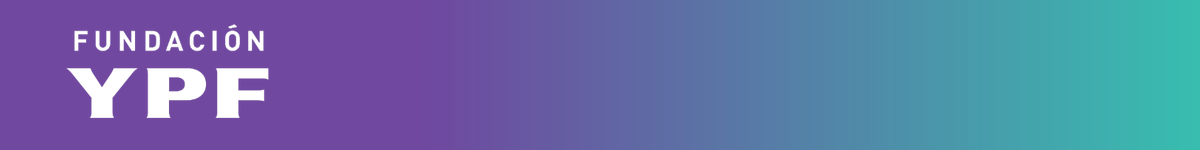

# Fundación YPF - Data Science

## Notebook 33: Puesta en producción y monitoreo de un modelo

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: de la red neuronal entrenada a su puesta en producción
* **Parte 2:** Pipeline de producción: reentrenamos el modelo
* **Parte 3:** Simulamos la puesta en producción: lote inicial y lotes posteriores
* **Parte 4:** Monitoreo del desempeño por lote
* **Parte 5:** Monitoreo de los datos: estadísticas y data drift
* **Parte 6:** Simulamos un drift controlado
* **Parte 7:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

En las clases 25 a 28 (Notebooks 29 a 32) construimos y entrenamos una red neuronal (MLPClassifier) para predecir si una paciente con cáncer de mama va a tener recurrencia, usando `cancer_mamario.csv`. Esta clase no entrena un modelo nuevo: toma ese mismo modelo ya entrenado y lo pone en producción, armando el pipeline que lo despliega y los controles que lo monitorean con el tiempo.

**Datasets:**

* `cancer_mamario.csv`: el mismo dataset de las Notebooks 31 y 32. Lo usamos en la parte guiada para reentrenar el modelo y simular su puesta en producción.
* `venta_autos.csv`: publicaciones de venta de autos usados, con fecha real de publicación. Lo usamos en el ejercicio de las salas para monitorear un modelo con lotes de tiempo reales, no simulados.

Antes de ejecutar, subí los archivos `cancer_mamario.csv` y `venta_autos.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from scipy.stats import ks_2samp

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Repaso: de la red neuronal entrenada a su puesta en producción

En las clases 25 a 28 vimos la teoría y práctica de redes neuronales: neurona, descenso por gradiente, entropía cruzada, forward y backpropagation, perceptrón multicapa, funciones de activación y regularización, y entrenamos un MLPClassifier sobre `cancer_mamario.csv`.

Hoy vimos cuatro conceptos nuevos que conectan ese modelo entrenado con su uso real:

* **Puesta en producción:** el momento en que el modelo deja de ser un experimento y empieza a recibir datos reales, predecir y que esos resultados se usen. Se estima que el 90% de los modelos de ML nunca llegan a esta etapa.
* **MLOps:** el conjunto de prácticas (infraestructura, versionado de modelos, pipelines automatizados, monitoreo) que busca reducir la fricción entre entrenar un modelo y usarlo en producción.
* **Pipeline:** un único objeto que empaqueta todos los pasos, desde el preprocesamiento de los datos hasta la predicción del modelo, para que entrenar y predecir sean siempre el mismo proceso reproducible.
* **Monitoreo de modelos:** una vez en producción, hay que medir qué tan bien sigue funcionando el modelo con el tiempo, porque los datos de entrenamiento y los de producción empiezan a diferir (data drift) y el desempeño del modelo puede empeorar (concept drift).

En esta notebook aplicamos los cuatro conceptos sobre el modelo de cáncer de mama: lo reentrenamos dentro de un pipeline de sklearn (Parte 2), simulamos que se pone en producción y recibe pacientes nuevas en lotes sucesivos (Parte 3), monitoreamos su desempeño por lote (Parte 4), monitoreamos los datos que recibe (Parte 5) y mostramos qué pasa cuando esos datos cambian (Parte 6).

## Parte 2: Pipeline de producción: reentrenamos el modelo

Repetimos el mismo preprocesamiento y arquitectura de la Notebook 32 (dos capas ocultas de 16 y 8 neuronas, activación ReLU), pero esta vez el escalado y el modelo quedan empaquetados en un único `Pipeline` de sklearn. Esto es lo que se pondría en producción: un solo objeto que recibe datos crudos y devuelve una predicción, sin pasos sueltos que alguien pueda olvidar o aplicar en el orden equivocado.

In [2]:
if not os.path.exists("cancer_mamario.csv"):
    from google.colab import files
    files.upload()

cancer = pd.read_csv("cancer_mamario.csv")

filas_antes = len(cancer)
cancer_limpio = cancer[(cancer != "?").all(axis=1)].copy()
print(f"Filas antes de sacar los '?': {filas_antes}. Filas después: {len(cancer_limpio)}")

cancer_limpio["target"] = (cancer_limpio["class"] == "recurrence-events").astype(int)

columnas_categoricas = ["age", "menopause", "tumor-size", "inv-nodes", "node-caps",
                         "breast", "breast-quad", "irradiat"]
X = pd.get_dummies(cancer_limpio[columnas_categoricas + ["deg-malig"]], columns=columnas_categoricas)
y = cancer_limpio["target"]
print("Features después del one-hot encoding:", X.shape[1])

Filas antes de sacar los '?': 286. Filas después: 277
Features después del one-hot encoding: 39


In [3]:
X_train, X_prod, y_train, y_prod = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Entrenamiento:", X_train.shape)
print("Reservado para simular producción:", X_prod.shape)

Entrenamiento: (207, 39)
Reservado para simular producción: (70, 39)


Las pacientes de `X_train` son las que el modelo ya vio al entrenar, igual que en la Notebook 32. Las de `X_prod` nunca se usaron para entrenar: las reservamos para simular que son pacientes nuevas que van a llegar al sistema una vez que el modelo esté en producción.

Cantidad de iteraciones hasta converger: 664


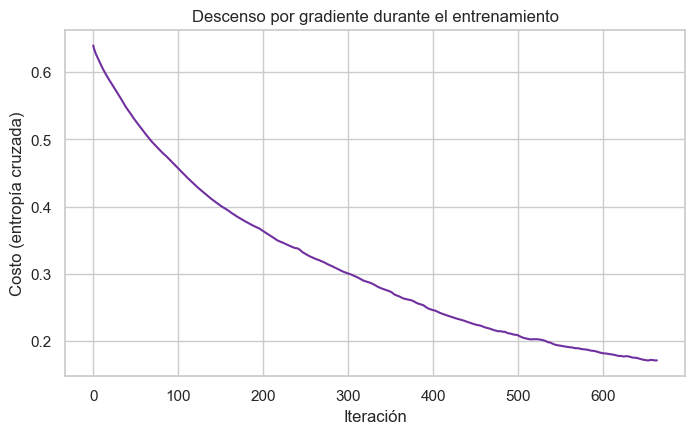

In [4]:
pipeline_modelo = Pipeline([
    ("escalado", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])
pipeline_modelo.fit(X_train, y_train)

print(f"Cantidad de iteraciones hasta converger: {pipeline_modelo.named_steps['mlp'].n_iter_}")

plt.figure(figsize=(8, 4.5))
plt.plot(pipeline_modelo.named_steps["mlp"].loss_curve_, color="#7030A0")
plt.xlabel("Iteración")
plt.ylabel("Costo (entropía cruzada)")
plt.title("Descenso por gradiente durante el entrenamiento")
plt.show()

El pipeline converge en 664 iteraciones, el mismo numero que obtuvimos en la Notebook 32 con el mismo split y la misma arquitectura: como es exactamente el mismo preprocesamiento y los mismos datos de entrenamiento, el resultado es reproducible. La curva de costo baja de forma sostenida y se aplana hacia el final, la misma forma que vimos en la Notebook 32. A partir de aca, `pipeline_modelo` es el objeto que se pondria en produccion: recibe pacientes nuevas sin preprocesar (sin escalar) y devuelve la prediccion.

## Parte 3: Simulamos la puesta en producción: lote inicial y lotes posteriores

En producción, el modelo no recibe todas las pacientes de una vez: las va recibiendo de a poco, con el correr del tiempo. El dataset `cancer_mamario.csv` no tiene una fecha real de cuándo se atendió a cada paciente, así que simulamos el paso del tiempo dividiendo a las pacientes de `X_prod` (las que separamos en la Parte 2 y el modelo nunca entrenó) en varios lotes sucesivos. Lo documentamos como una simulación: el orden de los lotes es arbitrario, no corresponde a fechas reales.

In [5]:
N_LOTES = 4
lotes_X = np.array_split(X_prod, N_LOTES)
lotes_y = np.array_split(y_prod, N_LOTES)

for i, (lote_x, lote_y) in enumerate(zip(lotes_X, lotes_y)):
    print(f"Lote {i}: {len(lote_x)} pacientes, {int(lote_y.sum())} con recurrencia")

Lote 0: 18 pacientes, 6 con recurrencia
Lote 1: 18 pacientes, 3 con recurrencia
Lote 2: 17 pacientes, 8 con recurrencia
Lote 3: 17 pacientes, 3 con recurrencia


## Parte 4: Monitoreo del desempeño por lote

A medida que llega cada lote, el sistema en producción puede comparar la predicción del modelo con el diagnóstico real (cuando finalmente se conoce) y calcular métricas de desempeño, igual que hicimos en la Notebook 32 con el conjunto de prueba, pero ahora lote por lote.

In [6]:
metricas_lotes = []
for i, (lote_x, lote_y) in enumerate(zip(lotes_X, lotes_y)):
    pred = pipeline_modelo.predict(lote_x)
    metricas_lotes.append({
        "lote": i,
        "n_pacientes": len(lote_x),
        "exactitud": accuracy_score(lote_y, pred),
        "f1_recurrencia": f1_score(lote_y, pred, pos_label=1, zero_division=0),
    })

metricas_df = pd.DataFrame(metricas_lotes)
metricas_df

,lote,n_pacientes,exactitud,f1_recurrencia
0,0,18,0.777778,0.666667
1,1,18,0.666667,0.400000
2,2,17,0.588235,0.363636
3,3,17,0.764706,0.333333


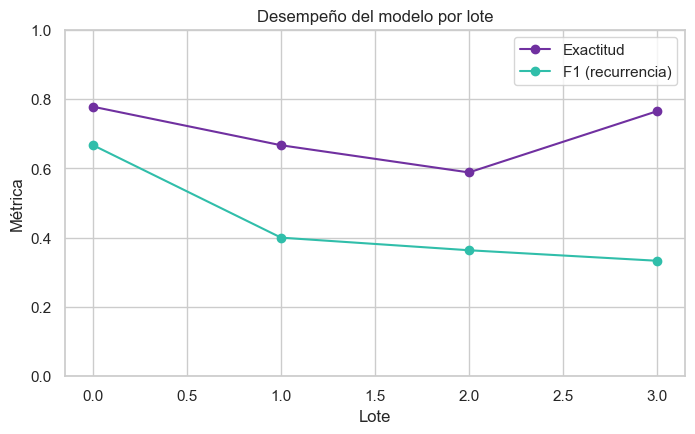

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(metricas_df["lote"], metricas_df["exactitud"], "o-", color="#7030A0", label="Exactitud")
ax.plot(metricas_df["lote"], metricas_df["f1_recurrencia"], "o-", color="#30BEAA", label="F1 (recurrencia)")
ax.set_xlabel("Lote")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1)
ax.set_title("Desempeño del modelo por lote")
ax.legend()
plt.show()

El desempeno varia de lote a lote: la exactitud va de 0.588 (lote 2) a 0.778 (lote 0), y el F1 de recurrencia de 0.333 (lote 3) a 0.667 (lote 0). Con lotes tan chicos (17 u 18 pacientes cada uno) una sola paciente mal clasificada cambia bastante la metrica, asi que esta variacion es en gran parte ruido estadistico, no necesariamente un problema real del modelo. Esto es, en si, una leccion de monitoreo: con lotes chicos hay que mirar la tendencia general, y no cada lote aislado, antes de alarmarse por una caida puntual.

## Parte 5: Monitoreo de los datos: estadísticas y data drift

Medir el desempeño por lote requiere conocer el diagnóstico real, que en producción puede tardar en llegar (o no llegar nunca para todas las pacientes). Por eso también monitoreamos directamente los datos de entrada: comparamos sus estadísticas con las del set de entrenamiento y usamos una prueba de Kolmogorov-Smirnov (KS) para detectar si la distribución de una variable cambió (data drift). La aplicamos sobre `deg-malig`, la única variable que quedó numérica (el resto son categóricas con one-hot encoding).

In [8]:
media_train = X_train["deg-malig"].mean()
desvio_train = X_train["deg-malig"].std()
print(f"Entrenamiento - deg-malig: media {media_train:.2f}, desvío {desvio_train:.2f}")

resultados_drift = []
for i, lote_x in enumerate(lotes_X):
    estadistico, p_valor = ks_2samp(X_train["deg-malig"], lote_x["deg-malig"])
    resultados_drift.append({
        "lote": i,
        "media": lote_x["deg-malig"].mean(),
        "desvio": lote_x["deg-malig"].std(),
        "ks_estadistico": estadistico,
        "ks_p_valor": p_valor,
    })

drift_df = pd.DataFrame(resultados_drift)
drift_df

Entrenamiento - deg-malig: media 2.06, desvío 0.74


,lote,media,desvio,ks_estadistico,ks_p_valor
0,0,2.222222,0.732084,0.084541,0.999022
1,1,2.111111,0.676400,0.079710,0.999633
2,2,2.000000,0.612372,0.127877,0.928953
3,3,1.882353,0.781213,0.106564,0.984253


En los cuatro lotes el p-valor del test KS es muy alto (entre 0.93 y 0.9996, muy por encima del umbral habitual de 0.05), asi que no hay evidencia de que la distribucion de `deg-malig` haya cambiado respecto del entrenamiento. Tiene sentido: estos lotes salen del mismo dataset que el entrenamiento, simplemente los reservamos aparte. Es el resultado esperado cuando no hay drift real, y nos sirve de referencia para comparar con la Parte 6.

## Parte 6: Simulamos un drift controlado

Hasta acá, los lotes vienen del mismo dataset que el entrenamiento, así que no deberían mostrar drift real. Para ver cómo el monitoreo detecta un cambio de verdad, simulamos un escenario documentado: imaginamos que, por un cambio externo (por ejemplo, un nuevo protocolo que deriva más pacientes con diagnósticos avanzados a este centro), el último lote empieza a tener un grado de malignidad más alto que el de entrenamiento. Lo simulamos subiendo artificialmente `deg-malig` en ese lote, con un tope de 3 (el valor máximo posible en la variable original). Esto es un dato simulado para mostrar cómo funciona el monitoreo, no un resultado real del dataset.

In [9]:
lote_con_drift = lotes_X[-1].copy()
y_lote_con_drift = lotes_y[-1]

print("deg-malig antes del drift simulado: media", round(lote_con_drift["deg-malig"].mean(), 2),
      "desvio", round(lote_con_drift["deg-malig"].std(), 2))

lote_con_drift["deg-malig"] = (lote_con_drift["deg-malig"] + 1).clip(upper=3)

print("deg-malig después del drift simulado: media", round(lote_con_drift["deg-malig"].mean(), 2),
      "desvio", round(lote_con_drift["deg-malig"].std(), 2))

estadistico_drift, p_valor_drift = ks_2samp(X_train["deg-malig"], lote_con_drift["deg-malig"])
print(f"KS contra entrenamiento: estadístico {estadistico_drift:.3f}, p-valor {p_valor_drift:.4f}")

deg-malig antes del drift simulado: media 1.88 desvio 0.78
deg-malig después del drift simulado: media 2.65 desvio 0.49
KS contra entrenamiento: estadístico 0.343, p-valor 0.0375


In [10]:
pred_drift = pipeline_modelo.predict(lote_con_drift)
exactitud_drift = accuracy_score(y_lote_con_drift, pred_drift)
f1_drift = f1_score(y_lote_con_drift, pred_drift, pos_label=1, zero_division=0)

exactitud_original = metricas_df.loc[metricas_df["lote"] == N_LOTES - 1, "exactitud"].iloc[0]
f1_original = metricas_df.loc[metricas_df["lote"] == N_LOTES - 1, "f1_recurrencia"].iloc[0]

print(f"Exactitud con el lote modificado: {exactitud_drift:.3f} (era {exactitud_original:.3f} sin el drift)")
print(f"F1 (recurrencia) con el lote modificado: {f1_drift:.3f} (era {f1_original:.3f} sin el drift)")

Exactitud con el lote modificado: 0.647 (era 0.765 sin el drift)
F1 (recurrencia) con el lote modificado: 0.250 (era 0.333 sin el drift)


El drift simulado se nota en los tres frentes que vimos en la teoria. En los datos: la media de `deg-malig` en el lote pasa de 1.88 a 2.65, y el test KS ahora da un p-valor de 0.0375 (por debajo de 0.05), asi que el monitoreo lo marcaria como data drift, a diferencia de los p-valores altos de la Parte 5. En el desempeno: la exactitud cae de 0.765 a 0.647 y el F1 de recurrencia de 0.333 a 0.250. Esto reproduce lo que decian las slides de hoy: cuando los datos de produccion empiezan a diferir de los de entrenamiento, el desempeno del modelo se resiente, y el monitoreo de los datos de entrada puede anticipar ese problema antes incluso de conocer el diagnostico real de las pacientes.

## Parte 7: Ejercicio para las salas de Zoom

**Dataset:** `venta_autos.csv`. A diferencia de `cancer_mamario.csv`, este dataset tiene una fecha real de publicación (`dateCrawled`), así que acá los lotes de tiempo no son una simulación: son semanas reales.

**Contexto:** van a entrenar un modelo que predice si un auto publicado tiene daño sin reparar (`notRepairedDamage`), y después lo van a monitorear con los lotes reales por semana, repitiendo el proceso de las Partes 2 a 6 pero con datos propios.

Les dejamos el dataset cargado, limpio de valores extremos y con la variable de tiempo ya construida; el resto queda para ustedes.

In [11]:
if not os.path.exists("venta_autos.csv"):
    from google.colab import files
    files.upload()

autos = pd.read_csv("venta_autos.csv")

autos["fecha_publicacion"] = pd.to_datetime(autos["dateCrawled"], format="%d/%m/%Y %H:%M", errors="coerce")

filtro_valido = (
    (autos["price"] > 100) & (autos["price"] < 100000)
    & (autos["yearOfRegistration"] >= 1950) & (autos["yearOfRegistration"] <= 2016)
    & (autos["powerPS"] >= 20) & (autos["powerPS"] <= 600)
)
autos_limpio = autos[filtro_valido].dropna(
    subset=["notRepairedDamage", "gearbox", "vehicleType", "fuelType", "fecha_publicacion"]
).copy()

autos_limpio["target"] = (autos_limpio["notRepairedDamage"] == "yes").astype(int)
autos_limpio["semana"] = autos_limpio["fecha_publicacion"].dt.isocalendar().week

print("Filas antes de limpiar:", len(autos), "Filas después:", len(autos_limpio))
print(autos_limpio["semana"].value_counts().sort_index())

Filas antes de limpiar: 50001 Filas después: 33972
semana
9     1359
10    7583
11    7169
12    7650
13    8319
14    1892
Name: count, dtype: Int64


In [12]:
# 1. Preprocesamiento: elegir columnas numericas (por ejemplo price, yearOfRegistration, powerPS, kilometer)
# y categoricas (por ejemplo vehicleType, gearbox, fuelType), hacer one-hot encoding de las categoricas con
# pd.get_dummies, y separar en X e y (sin usar notRepairedDamage ni target como feature).
# COMPLETAR

In [13]:
# 2. Elegir una semana temprana para entrenar (por ejemplo la primera semana disponible en autos_limpio)
# y entrenar un Pipeline de sklearn con StandardScaler + MLPClassifier sobre esos datos.
# COMPLETAR

In [14]:
# 3. Con las semanas que no se usaron para entrenar, calcular exactitud y F1 por semana
# (usando el pipeline ya entrenado, sin volver a entrenarlo) y graficar la evolucion.
# COMPLETAR

In [15]:
# 4. Elegir una variable numerica (por ejemplo powerPS o price) y comparar su media, desvio
# y el resultado de ks_2samp en cada semana contra la semana de entrenamiento.
# COMPLETAR

In [16]:
# 5. Conclusion: hubo data drift real entre semanas? el desempeno del modelo cambio con el tiempo?
# COMPLETAR